## Anamoly detection model


In [1]:

from pathlib import Path

file_path = Path(
    r"C:\docx\Predictive_Maintenance\src\data_preparation.py"
)

python_code = r'''
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = (
    r"C:\docx\Predictive_Maintenance\data"
    r"\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv"
)

FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

TARGET = "Machine failure"

CATEGORICAL_FEATURES = ["Type"]

NUMERICAL_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]


def load_data(path=DATA_PATH):
    return pd.read_csv(path)


def prepare_data(df):
    X = df[FEATURES].copy()
    y = df[TARGET].copy()

    return train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
'''

file_path.write_text(python_code.strip() + "\n", encoding="utf-8")

print("File saved:", file_path)
print("File size:", file_path.stat().st_size, "bytes")
print("\nFirst five lines:")
print("\n".join(file_path.read_text(encoding="utf-8").splitlines()[:5]))


File saved: C:\docx\Predictive_Maintenance\src\data_preparation.py
File size: 870 bytes

First five lines:
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = (
    r"C:\docx\Predictive_Maintenance\data"


In [5]:
import os

print("Current directory:", os.getcwd())

Current directory: C:\docx\Predictive_Maintenance\Notebooks


In [6]:
import os
import sys

PROJECT_PATH = r"C:\docx\Predictive_Maintenance"

os.chdir(PROJECT_PATH)

if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

print("Working directory:", os.getcwd())

Working directory: C:\docx\Predictive_Maintenance


In [7]:
import src.data_preparation as dp

print("Module imported successfully.")
print("Functions available:", hasattr(dp, "load_data"),
      hasattr(dp, "prepare_data"))

Module imported successfully.
Functions available: True True


In [8]:
import importlib
import src.data_preparation as dp

importlib.reload(dp)

print("load_data exists:", hasattr(dp, "load_data"))
print("prepare_data exists:", hasattr(dp, "prepare_data"))

load_data exists: True
prepare_data exists: True


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from src.data_preparation import (
    load_data,
    prepare_data,
    FEATURES,
    TARGET,
    CATEGORICAL_FEATURES,
    NUMERICAL_FEATURES
)

print("All shared functions imported successfully!")

All shared functions imported successfully!


In [10]:

df = load_data()

X_train, X_test, y_train, y_test = prepare_data(df)

print("Dataset shape:", df.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining failure distribution:")
print(y_train.value_counts())

print("\nTesting failure distribution:")
print(y_test.value_counts())


Dataset shape: (10000, 14)
Training shape: (8000, 6)
Testing shape: (2000, 6)

Training failure distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing failure distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [11]:

anomaly_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES
        )
    ]
)

print("Anomaly preprocessing created.")


Anomaly preprocessing created.


In [12]:

anomaly_model = Pipeline([
    ("preprocessing", anomaly_preprocessor),
    ("detector", IsolationForest(
        n_estimators=200,
        contamination="auto",
        max_samples="auto",
        random_state=42,
        n_jobs=-1
    ))
])

anomaly_model.fit(X_train)

print("Isolation Forest trained successfully.")


Isolation Forest trained successfully.


In [13]:
anomaly_labels = anomaly_model.predict(X_test)

# Reverse the sign so higher scores indicate greater abnormality
anomaly_scores = -anomaly_model.decision_function(X_test)

anomaly_results = pd.DataFrame({
    "Actual Failure": y_test,
    "Anomaly Flag": (anomaly_labels == -1).astype(int),
    "Anomaly Score": anomaly_scores
}, index=X_test.index)

print("Anomaly predictions generated successfully.")

print("\nAnomaly flag counts:")
print(anomaly_results["Anomaly Flag"].value_counts())

display(anomaly_results.head())


Anomaly predictions generated successfully.

Anomaly flag counts:
Anomaly Flag
0    1322
1     678
Name: count, dtype: int64


,Actual Failure,Anomaly Flag,Anomaly Score
2997,0,0,-0.017708
4871,0,0,-0.025704
3858,0,0,-0.047933
951,0,1,0.117857
6463,0,1,0.078739


# global feature sensitivity


In [14]:
from sklearn.utils import check_random_state

# Use a sample of test observations to reduce computation
X_eval = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
).copy()

# Higher scores mean more anomalous
baseline_scores = -anomaly_model.decision_function(X_eval)

rng = check_random_state(42)
importance_results = []

# Shuffle one feature at a time
for feature in X_eval.columns:
    changes = []

    for _ in range(10):
        X_permuted = X_eval.copy()

        X_permuted[feature] = rng.permutation(
            X_permuted[feature].to_numpy()
        )

        permuted_scores = -anomaly_model.decision_function(
            X_permuted
        )

        score_change = np.mean(
            np.abs(permuted_scores - baseline_scores)
        )

        changes.append(score_change)

    importance_results.append({
        "Feature": feature,
        "Mean Score Change": np.mean(changes),
        "Std Score Change": np.std(changes)
    })

importance_df = pd.DataFrame(
    importance_results
).sort_values(
    "Mean Score Change",
    ascending=False
)

display(importance_df)


,Feature,Mean Score Change,Std Score Change
0,Type,0.038183,0.001273
2,Process temperature [K],0.016474,0.000470
1,Air temperature [K],0.015905,0.000299
4,Torque [Nm],0.014800,0.000398
3,Rotational speed [rpm],0.014233,0.000407
5,Tool wear [min],0.012827,0.000454


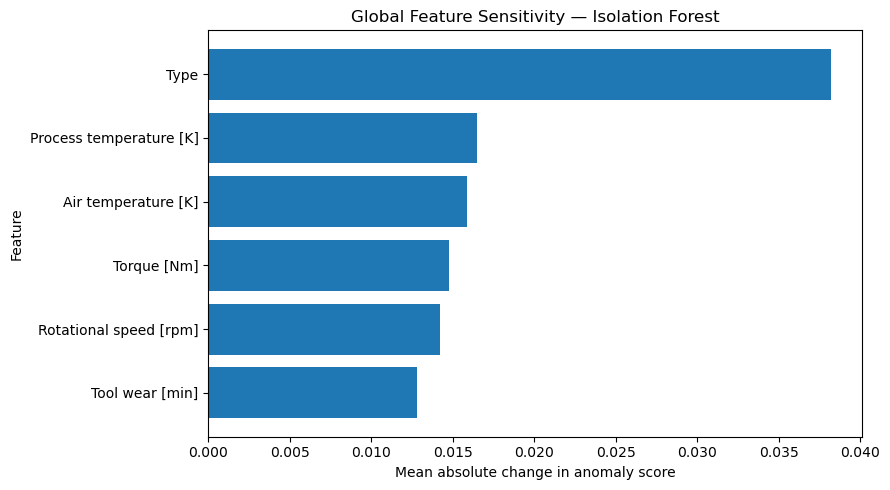

In [15]:
importance_plot = importance_df.sort_values(
    "Mean Score Change"
)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Mean Score Change"]
)

plt.xlabel("Mean absolute change in anomaly score")
plt.ylabel("Feature")
plt.title("Global Feature Sensitivity — Isolation Forest")
plt.tight_layout()
plt.show()


In [16]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [17]:

import shap
import pandas as pd
import numpy as np

# Select background observations
background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
).copy()

# Select the five most anomalous test observations
top_anomalies = anomaly_results.nlargest(
    5, "Anomaly Score"
)

X_explain = X_test.loc[top_anomalies.index].copy()

# Encode the categorical feature for SHAP's masker
type_categories = sorted(X_train["Type"].unique())

def encode_for_shap(data):
    if isinstance(data, pd.DataFrame):
        data = data[FEATURES].copy()
    else:
        data = pd.DataFrame(data, columns=FEATURES)

    data["Type"] = pd.Categorical(
        data["Type"],
        categories=type_categories
    ).codes

    return data.astype(float)

def decode_from_shap(data):
    data = pd.DataFrame(data, columns=FEATURES)

    type_codes = np.rint(data["Type"]).astype(int)
    data["Type"] = [
        type_categories[code]
        if 0 <= code < len(type_categories)
        else type_categories[0]
        for code in type_codes
    ]

    return data

# Explain the Isolation Forest anomaly score
def anomaly_score_fn(data):
    encoded_data = encode_for_shap(data)
    original_data = decode_from_shap(encoded_data)

    return -anomaly_model.decision_function(original_data)

# Give SHAP a numeric background and numeric observations
background_encoded = encode_for_shap(background)
X_explain_encoded = encode_for_shap(X_explain)

explainer = shap.PermutationExplainer(
    anomaly_score_fn,
    background_encoded
)

shap_values = explainer(
    X_explain_encoded,
    max_evals=2 * len(FEATURES) * 10 + 1
)

print("SHAP explanations generated successfully.")


SHAP explanations generated successfully.


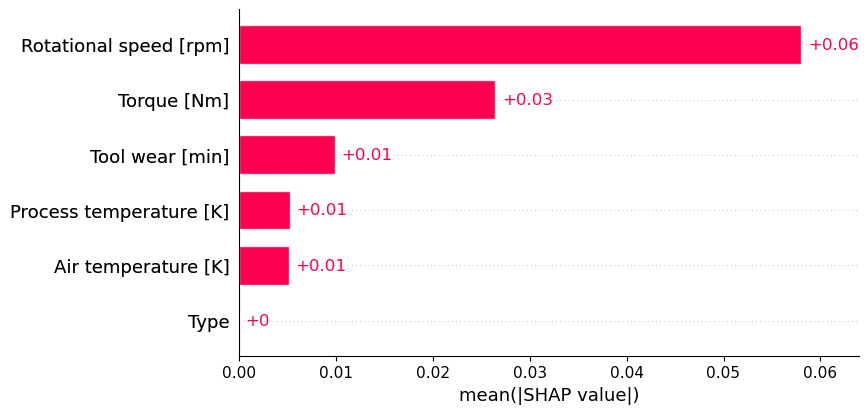

In [18]:
shap.plots.bar(shap_values)

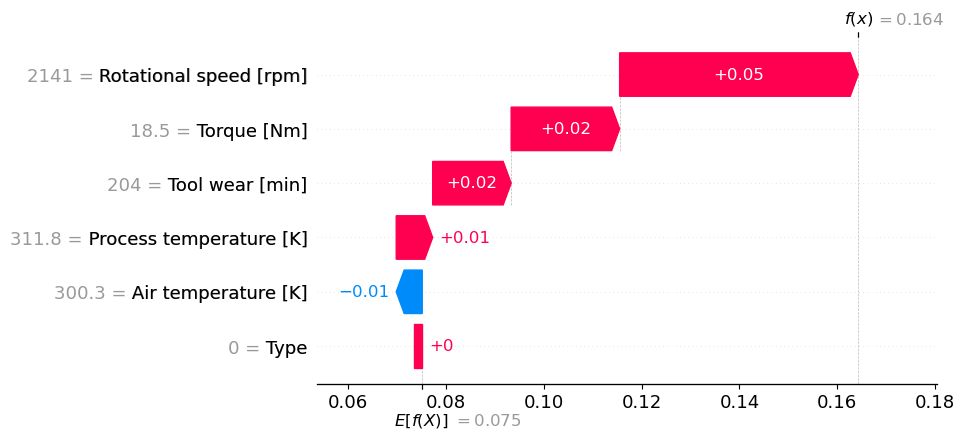

In [19]:
shap.plots.waterfall(shap_values[0])

In [20]:
import joblib

joblib.dump(
    anomaly_model,
    r"C:\docx\Predictive_Maintenance\isolation_forest.joblib"
)

print("Isolation Forest saved successfully.")

Isolation Forest saved successfully.
